In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap

from src.data.loader import load_raw_data, basic_clean
from src.features.engineering import add_behavioural_features, build_features_target
from src.features.splitting import stratified_split
from src.models.pipe import build_pipeline

df = basic_clean(load_raw_data())
df = add_behavioural_features(df)
X, y = build_features_target(df)
X_train, X_test, y_train, y_test = stratified_split(X, y, random_state=42)

pipe = build_pipeline('lightgbm', num_features=X_train.columns.tolist())
pipe.fit(X_train, y_train)
estimator = pipe.named_steps['estimator']

# tree-based SHAP explainers operate on raw (unscaled) values
X_sample = X_test.sample(n=min(2000, len(X_test)), random_state=42)
explainer = shap.TreeExplainer(estimator)
shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values
    if sv.ndim == 3:
        sv = sv[:, :, 1]
print('Explainer ready, shap matrix shape:', sv.shape)

2026-10-31 20:59:43,071 | INFO     | src.data.loader | load_raw_data:113 | Loading dataset from C:\All\why\data\raw\UCI_Credit_Card.csv


2026-10-31 20:59:43,394 | INFO     | src.models.registry | _apply_tuned:47 | Using tuned hyperparameters for lightgbm: {'n_estimators': 284, 'learning_rate': 0.03216078419470535, 'num_leaves': 57, 'max_depth': 3, 'min_child_samples': 23, 'subsample': 0.644639302316432, 'colsample_bytree': 0.816259298663039, 'reg_lambda': 0.0377837566557612}


Explainer ready, shap matrix shape: (2000, 61)


## Beeswarm — global feature importance
#
Each dot is a client. Red = high feature value, blue = low; x-axis = impact
on the predicted default probability.

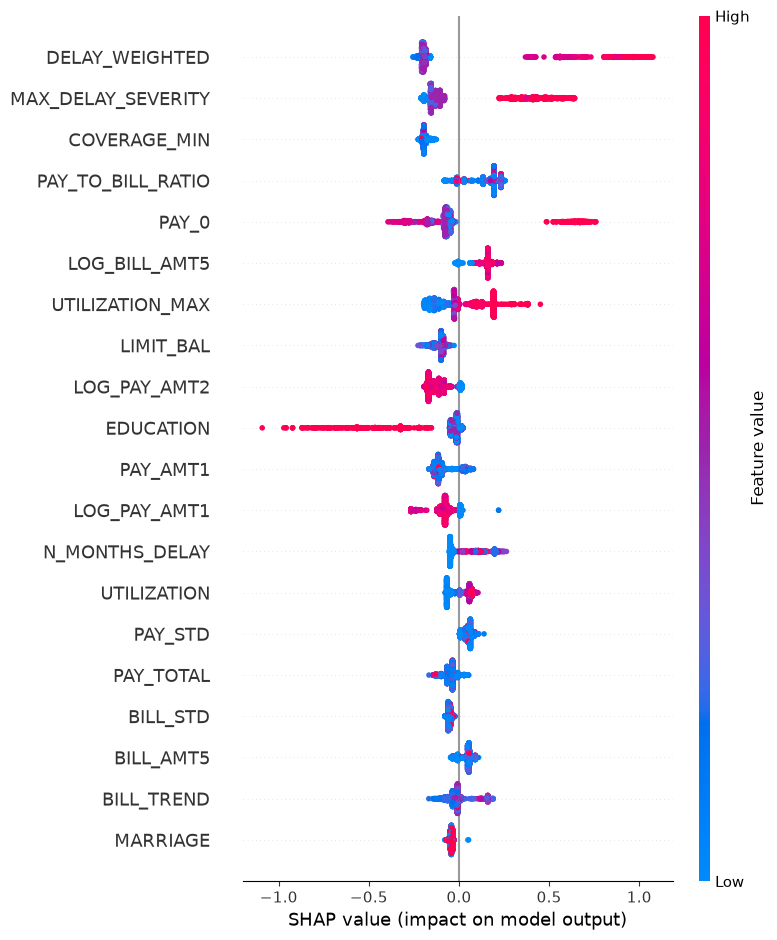

In [2]:
plt.figure(figsize=(9, 6))
shap.summary_plot(sv, X_sample, show=False)
plt.tight_layout()
plt.savefig('../reports/figures/04_shap_summary.png', dpi=110)
plt.show()

## Bar summary — mean absolute SHAP values

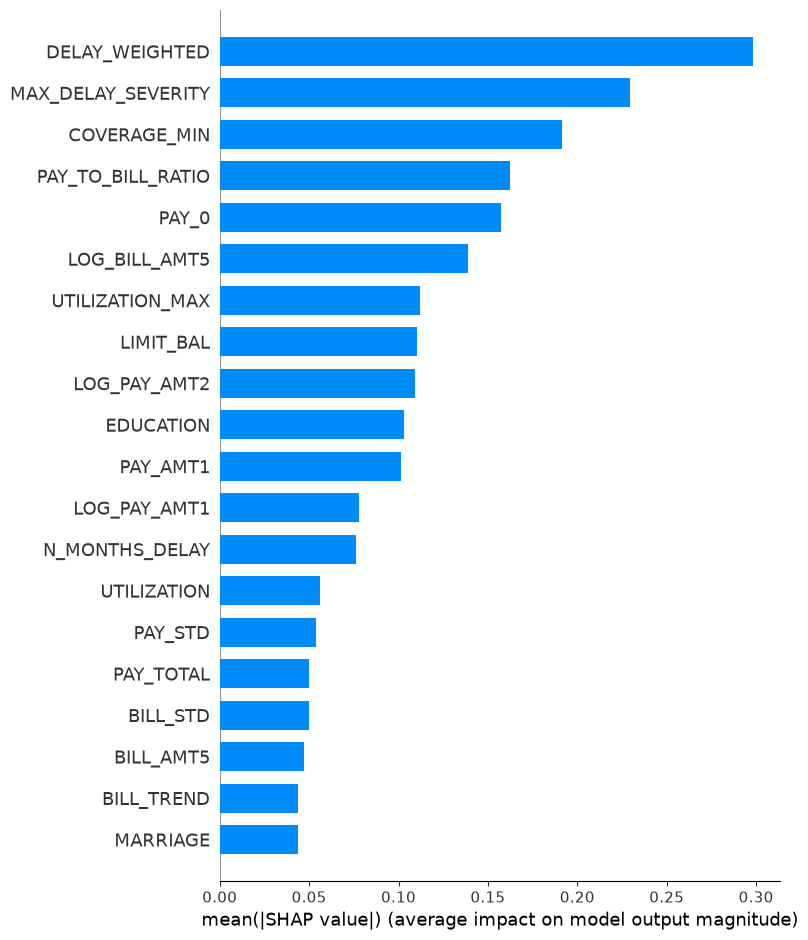

In [3]:
plt.figure(figsize=(8, 6))
shap.summary_plot(sv, X_sample, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('../reports/figures/04_shap_bar.png', dpi=110)
plt.show()